In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

In [3]:
df = pd.read_csv("Online_Retail.csv", encoding="ISO-8859-1")
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [5]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [6]:
print("Cancelled orders:", df["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Negative or zero quantity:", (df["Quantity"] <= 0).sum())
print("Zero or negative price:", (df["UnitPrice"] <= 0).sum())
print("Duplicate rows:", df.duplicated().sum())

Cancelled orders: 9288
Negative or zero quantity: 10624
Zero or negative price: 2517
Duplicate rows: 5268


In [7]:
# 1. Drop rows with no customer (RFM needs a customer)
df = df.dropna(subset=["CustomerID"])

# 2. Remove cancelled orders and bad quantities/prices
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# 3. Remove duplicate rows
df = df.drop_duplicates()

# 4. Fix types
df["CustomerID"] = df["CustomerID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# 5. Create the spending column
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print(df.shape)
print("Customers:", df["CustomerID"].nunique())

/tmp/ipykernel_2618/2998424734.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])


(392692, 9)
Customers: 4338


In [8]:
# Reference date: one day after the last purchase in the data
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

rfm.head()

Snapshot date: 2011-12-10 12:50:00


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [9]:
rfm.describe()

,CustomerID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2048.688081
std,1721.808492,100.014169,7.697998,8985.230220
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,306.482500
50%,15299.500000,51.000000,2.000000,668.570000
75%,16778.750000,142.000000,5.000000,1660.597500
max,18287.000000,374.000000,209.000000,280206.020000


In [10]:
# Recency: lower days = better, so the labels run 5 down to 1
rfm["R_Score"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)

# Frequency: many customers tie at 1 or 2 purchases, so rank first to avoid a "duplicate bins" error
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Monetary: higher spend = better
rfm["M_Score"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["RFM_Score"] = rfm["R_Score"] + rfm["F_Score"] + rfm["M_Score"]
rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,1,77183.60,1,1,5,7
1,12347,2,7,4310.00,5,5,5,15
2,12348,75,4,1797.24,2,4,4,10
3,12349,19,1,1757.55,4,1,4,9
4,12350,310,1,334.40,1,1,2,4


In [11]:
seg_map = {
    r"[1-2][1-2]": "Hibernating",
    r"[1-2][3-4]": "At Risk",
    r"[1-2]5": "Can't Lose Them",
    r"3[1-2]": "About to Sleep",
    r"33": "Need Attention",
    r"[3-4][4-5]": "Loyal Customers",
    r"41": "Promising",
    r"51": "New Customers",
    r"[4-5][2-3]": "Potential Loyalists",
    r"5[4-5]": "Champions",
}

rfm["Segment"] = (rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str)).replace(seg_map, regex=True)

rfm["Segment"].value_counts()


,count
Segment,
Hibernating,1065
Loyal Customers,827
Champions,633
At Risk,580
Potential Loyalists,492
About to Sleep,351
Need Attention,186
Promising,99
Can't Lose Them,63


In [12]:
segment_summary = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum"),
).round(1)

segment_summary["Customer_%"] = (segment_summary["Customers"] / segment_summary["Customers"].sum() * 100).round(1)
segment_summary["Revenue_%"] = (segment_summary["Total_Revenue"] / segment_summary["Total_Revenue"].sum() * 100).round(1)
segment_summary.sort_values("Total_Revenue", ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_%,Revenue_%
Segment,,,,,,,
Champions,633,5.9,12.4,6843.2,4331720.6,14.6,48.7
Loyal Customers,827,33.5,6.5,2848.3,2355571.7,19.1,26.5
At Risk,580,155.1,2.9,1072.9,622276.1,13.4,7.0
Hibernating,1065,217.9,1.1,486.7,518322.2,24.6,5.8
Potential Loyalists,492,17.1,2.0,1030.1,506813.6,11.3,5.7
Can't Lose Them,63,132.4,8.4,2790.1,175776.4,1.5,2.0
Need Attention,186,53.1,2.3,884.2,164468.6,4.3,1.9
About to Sleep,351,53.5,1.2,459.0,161108.1,8.1,1.8
Promising,99,23.4,1.0,353.3,34980.7,2.3,0.4


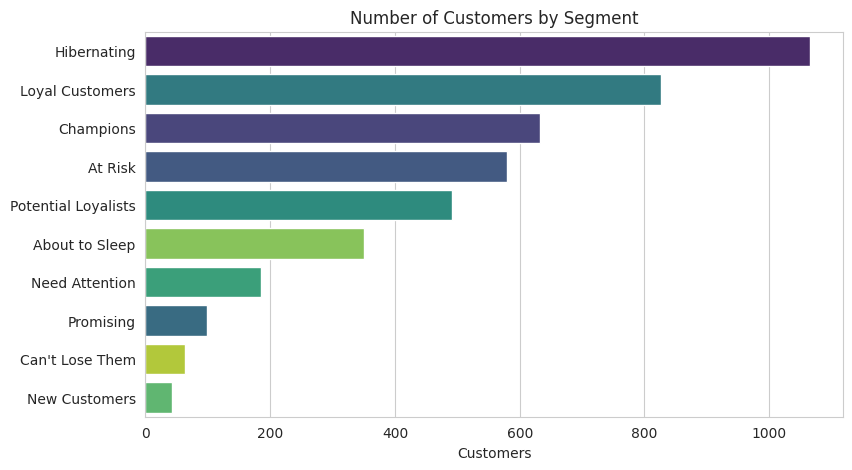

In [13]:
order = rfm["Segment"].value_counts().index
plt.figure(figsize=(9, 5))
sns.countplot(data=rfm, y="Segment", order=order, hue="Segment", palette="viridis", legend=False)
plt.title("Number of Customers by Segment")
plt.xlabel("Customers")
plt.ylabel("")
plt.show()

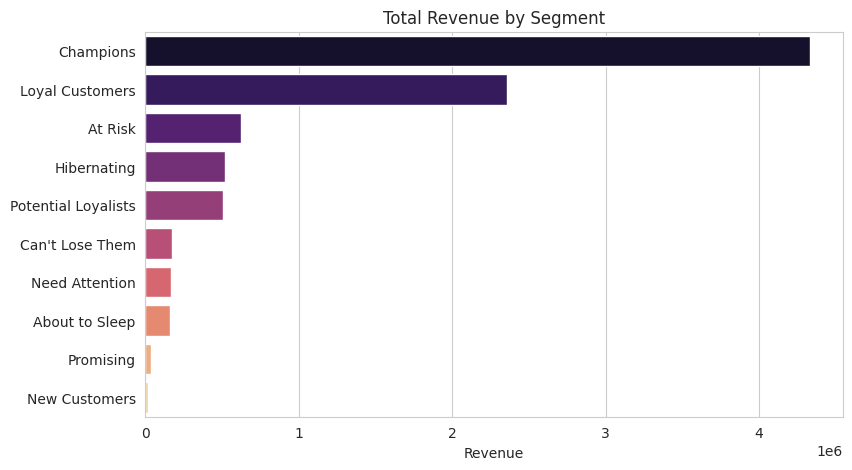

In [14]:
rev = rfm.groupby("Segment")["Monetary"].sum().sort_values(ascending=False).reset_index()
plt.figure(figsize=(9, 5))
sns.barplot(data=rev, y="Segment", x="Monetary", hue="Segment", palette="magma", legend=False)
plt.title("Total Revenue by Segment")
plt.xlabel("Revenue")
plt.ylabel("")
plt.show()

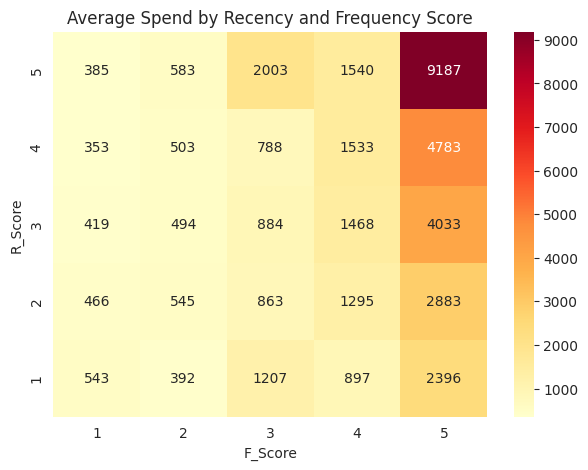

In [15]:
heat = rfm.pivot_table(values="Monetary", index="R_Score", columns="F_Score", aggfunc="mean")
plt.figure(figsize=(7, 5))
sns.heatmap(heat.sort_index(ascending=False), annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Average Spend by Recency and Frequency Score")
plt.show()

## Marketing Recommendations
| Segment | Who they are | Suggested action |
|---|---|---|
| Champions | Bought recently, often, and spend the most | Reward them: early access to new products, VIP perks, referral bonuses |
| Loyal Customers | Buy regularly with good spend | Loyalty points, upsell higher-value or bundled products |
| Potential Loyalists | Recent buyers with a few purchases | Membership offers and personalised recommendations to build the habit |
| New Customers | Just made a first purchase | Welcome email, onboarding discount on the second order |
| Promising | Recent but low frequency | Time-limited offers and product education |
| Need Attention | Average on all three | Limited-time deals and reminders |
| About to Sleep | Below-average recency and frequency | Re-engagement emails with a small discount |
| At Risk | Used to buy often, but not recently | Personalised "we miss you" campaign with a stronger offer |
| Can't Lose Them | Big past spenders who have gone quiet | Direct personal outreach, special win-back offer |
| Hibernating | Low on everything | Low-cost reactivation email; don't spend heavily on them |

In [16]:
rfm.to_csv("rfm_segments.csv", index=False)